# 02 — Avaliação Comparativa: Modelo Base vs Adaptadores LoRA

Este notebook unifica o benchmark comparativo dos modelos no conjunto de teste (`data/teste.jsonl`, 360 tarefas):
1. **Modelo Base** (`Qwen/Qwen3-1.7B` original, sem fine-tuning)
2. **LoRA r=8** (Adaptador compacto com 8.7M parâmetros)
3. **LoRA r=16** (Adaptador principal com 17.4M parâmetros)

Métricas avaliadas:
- **Exato (%)**: resposta rigorosamente idêntica ao padrão ISO 8601 (`AAAA-MM-DD` ou `AAAA-MM-DDTHH:MM`), sem texto excedente.
- **Conteúdo (%)**: a data correta está presente na resposta gerada.
- **Estratificação**: Variações (260 amostras) vs Famílias Inéditas (100 amostras).


In [1]:
# ==============================================================================
# CONTROLE DE EXECUÇÃO RÁPIDA (FAST-SKIP)
# ==============================================================================
# Se False: Carrega as predições de results/*.json e gera os placares/gráficos imediatamente.
# Se True:  Re-executa a inferência batch na GPU para os 360 itens de teste.
REEXECUTAR_AVALIACAO = True

## 1. Setup e Carregamento do Conjunto de Teste


In [2]:
import json
import time

import pandas as pd
import torch
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer

from common import (
    BASE,
    DIR_ADAPTERS,
    DIR_ASSETS,
    DIR_RESULTS,
    escolher_device,
    extrair_iso,
    gerar,
    ler_jsonl,
    prompt_chat,
)


def carregar(adaptador=None):
    """Carrega o modelo base em bf16 e, opcionalmente, anexa os pesos LoRA."""
    device = escolher_device()
    tok = AutoTokenizer.from_pretrained(BASE)
    tok.padding_side = "left"
    model = AutoModelForCausalLM.from_pretrained(
        BASE, dtype=torch.bfloat16 if device == "cuda" else torch.float32
    ).to(device)

    if adaptador is not None:
        model = PeftModel.from_pretrained(model, str(adaptador))

    model.eval()
    return model, tok


def avaliar(model, tok, exemplos, lote=32, max_new_tokens=24, mostrar=True):
    """Executa a inferência em lote e calcula acurácia exata e de conteúdo."""
    resultados = []
    for i in range(0, len(exemplos), lote):
        grupo = exemplos[i : i + lote]
        prompts = [prompt_chat(tok, e["referencia"], e["expressao"]) for e in grupo]
        respostas = gerar(model, tok, prompts, max_new_tokens=max_new_tokens)
        for ex, resp in zip(grupo, respostas):
            resultados.append({
                **ex,
                "gerado": resp,
                "exato": resp == ex["resposta"],
                "conteudo": extrair_iso(resp) == ex["resposta"],
            })
        if mostrar:
            print(f"  {min(i + lote, len(exemplos))}/{len(exemplos)} avaliados", end="\r")
    if mostrar:
        print()
    return resultados


def placar(resultados):
    """Gera matriz percentual de acurácia por tipo (Variação/Inédita) e Total."""
    df = pd.DataFrame(resultados)
    tabela = df.groupby("tipo")[["exato", "conteudo"]].mean()
    tabela.loc["TOTAL"] = df[["exato", "conteudo"]].mean()
    return (tabela * 100).round(1)


def placar_por_familia(resultados):
    """Gera matriz percentual de acurácia detalhada por família de expressão."""
    df = pd.DataFrame(resultados)
    return (df.groupby(["tipo", "familia"])[["exato", "conteudo"]].mean() * 100).round(1)


def salvar_resultados(nome, resultados):
    """Salva as predições detalhadas de cada modelo em results/<nome>.json."""
    DIR_RESULTS.mkdir(exist_ok=True)
    with open(DIR_RESULTS / f"{nome}.json", "w", encoding="utf-8") as arq:
        json.dump(resultados, arq, ensure_ascii=False, indent=2)


def ler_resultados(nome):
    """Carrega predições salvas em results/<nome>.json."""
    with open(DIR_RESULTS / f"{nome}.json", encoding="utf-8") as arq:
        return json.load(arq)


f:\CP5GenAI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
teste = ler_jsonl("teste")
print(f"Total de tarefas de teste: {len(teste)}")

Total de tarefas de teste: 360


## 2. Avaliação do Modelo Base (Qwen3-1.7B sem LoRA)


In [4]:
caminho_base_json = DIR_RESULTS / "base.json"

if not REEXECUTAR_AVALIACAO and caminho_base_json.exists():
    print("[FAST-SKIP] REEXECUTAR_AVALIACAO=False: Carregando resultados prévios do modelo base...")
    resultados_base = ler_resultados("base")
    print(f"Resultados do Modelo Base carregados: {len(resultados_base)} predições.")
else:
    print(f"Carregando modelo base: {BASE}...")
    t0 = time.time()
    modelo_base, tok = carregar(adaptador=None)
    resultados_base = avaliar(modelo_base, tok, teste, lote=32, max_new_tokens=24)
    salvar_resultados("base", resultados_base)
    del modelo_base
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print("Avaliação do modelo base concluída!")


Carregando modelo base: Qwen/Qwen3-1.7B...


Loading weights: 100%|██████████| 311/311 [00:01<00:00, 305.46it/s]


  360/360 avaliados
Avaliação do modelo base concluída!


## 3. Avaliação do Modelo LoRA r=8


In [5]:
caminho_r8_json = DIR_RESULTS / "lora_r8.json"
caminho_r8 = DIR_ADAPTERS / "lora_r8"

if not REEXECUTAR_AVALIACAO and caminho_r8_json.exists():
    print("[FAST-SKIP] REEXECUTAR_AVALIACAO=False: Carregando resultados prévios de LoRA r=8...")
    res_r8 = ler_resultados("lora_r8")
    print(f"Resultados de LoRA r=8 carregados: {len(res_r8)} predições.")
else:
    print(f"Carregando e avaliando {caminho_r8}...")
    t0 = time.time()
    model_r8, tok = carregar(adaptador=caminho_r8)
    res_r8 = avaliar(model_r8, tok, teste, lote=32, max_new_tokens=24)
    salvar_resultados("lora_r8", res_r8)
    del model_r8
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"LoRA r=8 avaliado em {time.time() - t0:.1f} s")


Carregando e avaliando F:\CP5GenAI\adapters\lora_r8...


Loading weights: 100%|██████████| 311/311 [00:01<00:00, 277.90it/s]


  360/360 avaliados
LoRA r=8 avaliado em 24.9 s


## 4. Avaliação do Modelo LoRA r=16 (Principal)


In [6]:
caminho_r16_json = DIR_RESULTS / "lora_r16.json"
caminho_r16 = DIR_ADAPTERS / "lora_r16"

if not REEXECUTAR_AVALIACAO and caminho_r16_json.exists():
    print("[FAST-SKIP] REEXECUTAR_AVALIACAO=False: Carregando resultados prévios de LoRA r=16...")
    res_r16 = ler_resultados("lora_r16")
    print(f"Resultados de LoRA r=16 carregados: {len(res_r16)} predições.")
else:
    print(f"Carregando e avaliando {caminho_r16}...")
    t0 = time.time()
    model_r16, tok = carregar(adaptador=caminho_r16)
    res_r16 = avaliar(model_r16, tok, teste, lote=32, max_new_tokens=24)
    salvar_resultados("lora_r16", res_r16)
    del model_r16
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"LoRA r=16 avaliado em {time.time() - t0:.1f} s")


Carregando e avaliando F:\CP5GenAI\adapters\lora_r16...


Loading weights: 100%|██████████| 311/311 [00:01<00:00, 303.48it/s]


  360/360 avaliados
LoRA r=16 avaliado em 24.9 s


## 5. Placar Geral Comparativo e Desempenho por Família


In [7]:
res_base = ler_resultados("base")

df_base = placar(res_base)
df_r8 = placar(res_r8)
df_r16 = placar(res_r16)

comparacao = pd.DataFrame({
    "Base Exato (%)": df_base["exato"],
    "LoRA r=8 Exato (%)": df_r8["exato"],
    "LoRA r=16 Exato (%)": df_r16["exato"],
    "Base Conteúdo (%)": df_base["conteudo"],
    "LoRA r=8 Conteúdo (%)": df_r8["conteudo"],
    "LoRA r=16 Conteúdo (%)": df_r16["conteudo"],
})

print("\n" + "=" * 80)
print("PLACAR GERAL COMPARATIVO")
print("=" * 80)
print(comparacao)
print("=" * 80)

# Salvar tabela comparativa
DIR_RESULTS.mkdir(exist_ok=True)
comparacao.to_csv(DIR_RESULTS / "placar_geral.csv")


PLACAR GERAL COMPARATIVO
          Base Exato (%)  LoRA r=8 Exato (%)  LoRA r=16 Exato (%)  \
tipo                                                                
inedita              3.0                56.0                 55.0   
variacao            16.5                85.4                 87.3   
TOTAL               12.8                77.2                 78.3   

          Base Conteúdo (%)  LoRA r=8 Conteúdo (%)  LoRA r=16 Conteúdo (%)  
tipo                                                                        
inedita                 3.0                   56.0                    55.0  
variacao               16.5                   85.4                    87.3  
TOTAL                  12.8                   77.2                    78.3  


In [8]:
fam_base = placar_por_familia(res_base)["exato"]
fam_r8 = placar_por_familia(res_r8)["exato"]
fam_r16 = placar_por_familia(res_r16)["exato"]

tabela_familias = pd.DataFrame({
    "Base (%)": fam_base,
    "LoRA r=8 (%)": fam_r8,
    "LoRA r=16 (%)": fam_r16,
})
print("\nDesempenho por Família (Exato %):")
print(tabela_familias)
tabela_familias.to_csv(DIR_RESULTS / "placar_familias.csv")


Desempenho por Família (Exato %):
                             Base (%)  LoRA r=8 (%)  LoRA r=16 (%)
tipo     familia                                                  
inedita  daqui_anos               0.0          56.0           64.0
         horas_atras              0.0          76.0           60.0
         meses_atras              4.0          64.0           68.0
         semanas_atras            8.0          28.0           28.0
variacao daqui_dias              10.0          70.0           85.0
         daqui_horas              0.0          85.0           80.0
         daqui_meses              5.0          80.0           80.0
         daqui_minutos            5.0         100.0           95.0
         daqui_semanas            5.0          55.0           60.0
         data_explicita          55.0          95.0          100.0
         dia_do_mes              40.0          85.0           85.0
         dia_relativo            40.0         100.0          100.0
         dia_semana_passado

## 6. Gráfico Comparativo de Acurácia e Generalização


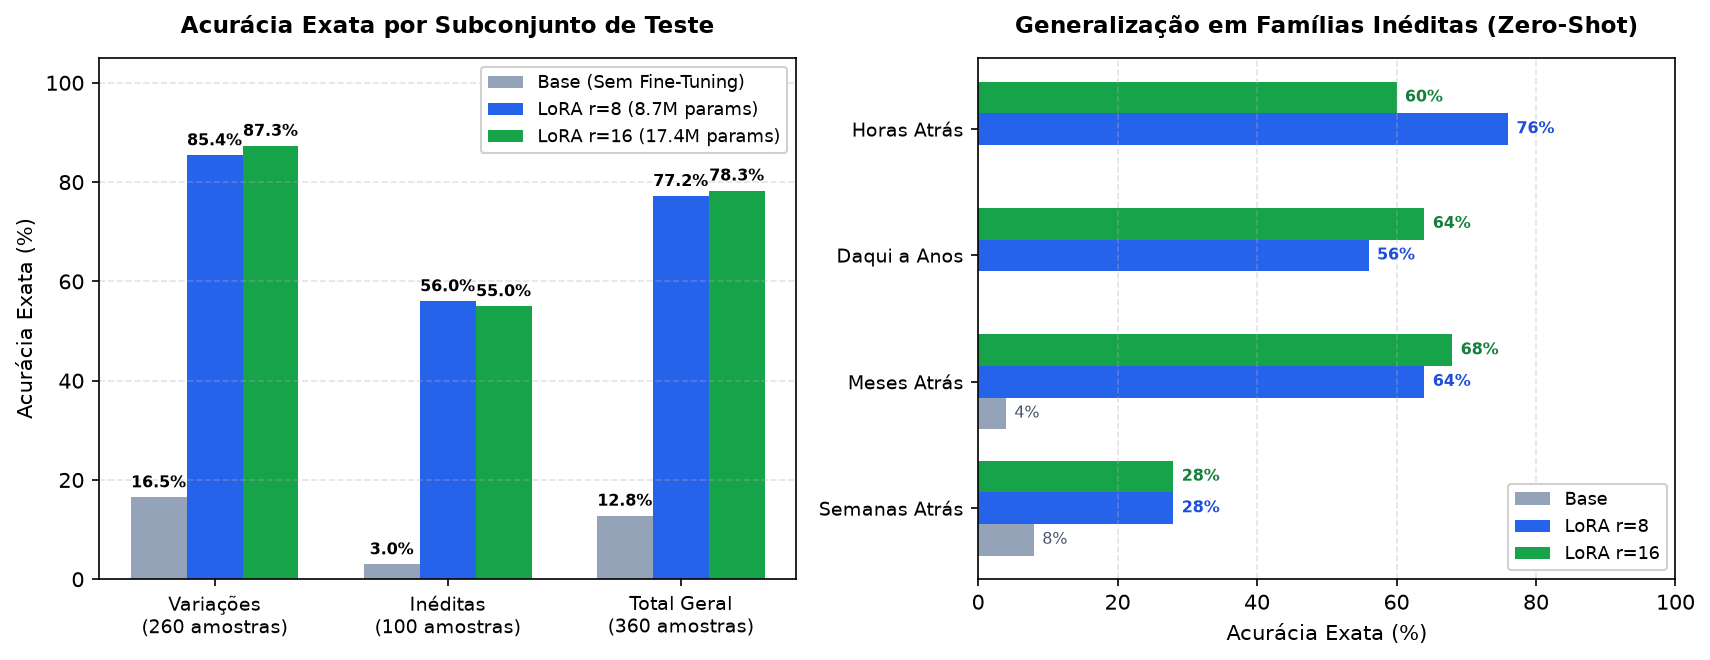

Gráfico comparativo salvo em: F:\CP5GenAI\assets\grafico_acuracia_comparacao.png


In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Gerar gráfico comparativo de acurácia
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5), dpi=150)

# Subplot 1: Subconjuntos de Teste
categorias = ['Variações\n(260 amostras)', 'Inéditas\n(100 amostras)', 'Total Geral\n(360 amostras)']
x = np.arange(len(categorias))
largura = 0.24

base_vals = [df_base.loc['variacao', 'exato'], df_base.loc['inedita', 'exato'], df_base.loc['TOTAL', 'exato']]
r8_vals = [df_r8.loc['variacao', 'exato'], df_r8.loc['inedita', 'exato'], df_r8.loc['TOTAL', 'exato']]
r16_vals = [df_r16.loc['variacao', 'exato'], df_r16.loc['inedita', 'exato'], df_r16.loc['TOTAL', 'exato']]

b0 = axes[0].bar(x - largura, base_vals, largura, label='Base (Sem Fine-Tuning)', color='#94a3b8')
b1 = axes[0].bar(x, r8_vals, largura, label='LoRA r=8 (8.7M params)', color='#2563eb')
b2 = axes[0].bar(x + largura, r16_vals, largura, label='LoRA r=16 (17.4M params)', color='#16a34a')

axes[0].set_title('Acurácia Exata por Subconjunto de Teste', fontsize=11, fontweight='bold', pad=12)
axes[0].set_ylabel('Acurácia Exata (%)', fontsize=10)
axes[0].set_xticks(x)
axes[0].set_xticklabels(categorias, fontsize=9)
axes[0].set_ylim(0, 105)
axes[0].grid(axis='y', linestyle='--', alpha=0.35)
axes[0].legend(fontsize=8.5, loc='upper right', framealpha=0.9)

for bars in [b0, b1, b2]:
    for bar in bars:
        h = bar.get_height()
        axes[0].annotate(f'{h:.1f}%',
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 3), textcoords='offset points',
            ha='center', va='bottom', fontsize=7.5, fontweight='bold')

# Subplot 2: Generalização em Famílias Inéditas
familias_ineditas = ['semanas_atras', 'meses_atras', 'daqui_anos', 'horas_atras']
rotulos_fam = ['Semanas Atrás', 'Meses Atrás', 'Daqui a Anos', 'Horas Atrás']
y = np.arange(len(familias_ineditas))
alt = 0.25

base_fam_vals = [fam_base.get(('inedita', f), 0.0) for f in familias_ineditas]
r8_fam_vals = [fam_r8.get(('inedita', f), 0.0) for f in familias_ineditas]
r16_fam_vals = [fam_r16.get(('inedita', f), 0.0) for f in familias_ineditas]

axes[1].barh(y - alt, base_fam_vals, alt, label='Base', color='#94a3b8')
axes[1].barh(y, r8_fam_vals, alt, label='LoRA r=8', color='#2563eb')
axes[1].barh(y + alt, r16_fam_vals, alt, label='LoRA r=16', color='#16a34a')

axes[1].set_title('Generalização em Famílias Inéditas (Zero-Shot)', fontsize=11, fontweight='bold', pad=12)
axes[1].set_xlabel('Acurácia Exata (%)', fontsize=10)
axes[1].set_yticks(y)
axes[1].set_yticklabels(rotulos_fam, fontsize=9)
axes[1].set_xlim(0, 100)
axes[1].grid(axis='x', linestyle='--', alpha=0.35)
axes[1].legend(fontsize=8.5, loc='lower right', framealpha=0.9)

for idx, (b_v, r8_v, r16_v) in enumerate(zip(base_fam_vals, r8_fam_vals, r16_fam_vals)):
    if b_v > 0:
        axes[1].annotate(f'{b_v:.0f}%', xy=(b_v + 1.2, idx - alt), va='center', fontsize=7.5, color='#475569')
    if r8_v > 0:
        axes[1].annotate(f'{r8_v:.0f}%', xy=(r8_v + 1.2, idx), va='center', fontsize=7.5, color='#1d4ed8', fontweight='bold')
    if r16_v > 0:
        axes[1].annotate(f'{r16_v:.0f}%', xy=(r16_v + 1.2, idx + alt), va='center', fontsize=7.5, color='#15803d', fontweight='bold')

plt.tight_layout()
DIR_ASSETS.mkdir(exist_ok=True)
caminho_acc = DIR_ASSETS / 'grafico_acuracia_comparacao.png'
plt.savefig(caminho_acc, dpi=150)
plt.show()
print(f'Gráfico comparativo salvo em: {caminho_acc}')

## 7. Demonstração Qualitativa Lado a Lado (Base vs LoRA r=16)


In [10]:
perguntas_demonstracao = [
    ("sexta-feira, 2026-10-09 14:30", "próxima terça às 3 da tarde", "2026-10-13T15:00"),
    ("segunda-feira, 2025-05-12 10:00", "depois de amanhã", "2025-05-14"),
    ("quarta-feira, 2024-03-20 18:00", "daqui a 3 semanas", "2024-04-10"),
    ("sábado, 2026-01-31 09:00", "fim do mês que vem", "2026-02-28"),
    ("terça-feira, 2025-11-04 15:30", "daqui a 45 minutos", "2025-11-04T16:15"),
    ("quinta-feira, 2027-08-19 12:00", "há 2 semanas (inédita)", "2027-08-05"),
]

# Carregar modelo treinado principal para demonstração interativa
model_treinado, tok = carregar(adaptador=caminho_r16)

print("\n" + "=" * 80)
print("COMPARAÇÃO VISUAL: ESPERADO vs RESPOSTA GERADA PELO MODELO TREINADO")
print("=" * 80)

for ref_str, expr, esperado in perguntas_demonstracao:
    # Gerar predição
    p = prompt_chat(tok, ref_str.split(", ")[1], expr)
    resp = gerar(model_treinado, tok, [p], max_new_tokens=24)[0]
    status = "✅ ACERTOU" if resp == esperado else "❌ ERROU"
    print(f"\n[Referência]: {ref_str}")
    print(f"[Expressão]:  {expr}")
    print(f"[Esperado]:   {esperado}")
    print(f"[Gerado]:     {resp!r}  -> {status}")

del model_treinado
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Loading weights: 100%|██████████| 311/311 [00:01<00:00, 307.13it/s]



COMPARAÇÃO VISUAL: ESPERADO vs RESPOSTA GERADA PELO MODELO TREINADO

[Referência]: sexta-feira, 2026-10-09 14:30
[Expressão]:  próxima terça às 3 da tarde
[Esperado]:   2026-10-13T15:00
[Gerado]:     '2026-10-13T15:00'  -> ✅ ACERTOU

[Referência]: segunda-feira, 2025-05-12 10:00
[Expressão]:  depois de amanhã
[Esperado]:   2025-05-14
[Gerado]:     '2025-05-14'  -> ✅ ACERTOU

[Referência]: quarta-feira, 2024-03-20 18:00
[Expressão]:  daqui a 3 semanas
[Esperado]:   2024-04-10
[Gerado]:     '2024-04-10'  -> ✅ ACERTOU

[Referência]: sábado, 2026-01-31 09:00
[Expressão]:  fim do mês que vem
[Esperado]:   2026-02-28
[Gerado]:     '2026-02-28'  -> ✅ ACERTOU

[Referência]: terça-feira, 2025-11-04 15:30
[Expressão]:  daqui a 45 minutos
[Esperado]:   2025-11-04T16:15
[Gerado]:     '2025-11-04T16:15'  -> ✅ ACERTOU

[Referência]: quinta-feira, 2027-08-19 12:00
[Expressão]:  há 2 semanas (inédita)
[Esperado]:   2027-08-05
[Gerado]:     '2027-08-05'  -> ✅ ACERTOU
